In [70]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add the repo root when the kernel starts in an experiment folder
if Path.cwd().parent.name == 'experiments':
    sys.path.append(str(Path.cwd().parents[1]))

from experiments.rate_ctrl import RateControllerLin
from rate_model import RateModelWC


In [80]:
np.random.seed(114)

N = 5

tau = 1.0
rho = 0.9
r0 = np.linspace(2, 8, N).reshape(-1, 1)
model, h0, J = RateModelWC.from_steady_state(
    r0, tau=tau, rmax=10, gain_slope=0.5, gain_center=0, R=rho
)

T = 120.0
dt = 0.05
nsteps = int(T / dt)
time = np.arange(0, nsteps * dt, dt)

sigma_h = 0.2
H = h0 + sigma_h * np.random.randn(N, nsteps) / np.sqrt(dt)
r_start = r0.copy()

r0_target = 3.0
pop_ctrl = 2
activate_t = 30.0
post_lock_eval_T = 20.0
ctrl_fast_par = {'tauu': 0.1, 'ku': 0.5}

#taum_grid = 2 ** np.arange(-5, -2, dtype=float)
taum_grid = np.linspace(0.02, 0.1, 5)
ks_grid = 2 ** np.arange(-2, 5, dtype=float)
delta_lock_grid = np.arange(10, 50, 10)

post_lock_nbins = int(round(post_lock_eval_T / dt))

In [78]:
def run_case(taum, ks, delta_lock):
    lock_t = activate_t + delta_lock
    ctrl = RateControllerLin(r0_target, taum=taum, ks=ks, **ctrl_fast_par)
    ctrl.begin(dt, nsteps, sim_res_type='final', activate_t=activate_t, lock_t=lock_t)

    rates = np.zeros((N, nsteps), dtype=float)
    rates[:, [0]] = r_start
    u_hist = np.full(nsteps, np.nan, dtype=float)

    for step in range(1, nsteps):
        r_prev = rates[:, [step - 1]]
        ctrl_state = ctrl.step(np.asarray(r_prev[[pop_ctrl]]))
        fb = np.zeros_like(r_prev)
        fb[pop_ctrl, 0] = ctrl_state['z'][0, 0]
        r_hat = model.gain(model.W @ r_prev + H[:, [step]] + fb)
        rates[:, [step]] = r_prev + (r_hat - r_prev) * dt / model.tau
        u_hist[step - 1] = ctrl_state['u'][0, 0]

    ctrl_rate = rates[pop_ctrl]
    active_mask = (time >= activate_t) & (time < lock_t)
    post_mask = (time >= lock_t) & (time < lock_t + post_lock_eval_T)

    if post_mask.sum() != post_lock_nbins:
        raise ValueError(f'post-lock window mismatch for lock_t={lock_t}')

    post_rate = ctrl_rate[post_mask]
    active_rate = ctrl_rate[active_mask]
    return {
        'taum': float(taum),
        'ks': float(ks),
        'delta_lock': float(delta_lock),
        'lock_t': float(lock_t),
        'post_lock_mean_rate': float(post_rate.mean()),
        'post_lock_abs_mean_error': float(abs(post_rate.mean() - r0_target)),
        'post_lock_std_rate': float(post_rate.std(ddof=0)),
        'pre_lock_mean_abs_error': float(np.mean(np.abs(active_rate - r0_target))),
        'pre_lock_u_rms': float(np.sqrt(np.mean(u_hist[active_mask] ** 2))),
    }


results = [
    run_case(taum, ks, delta_lock)
    for taum in taum_grid
    for ks in ks_grid
    for delta_lock in delta_lock_grid
]
results_df = pd.DataFrame(results).sort_values(['taum', 'ks', 'delta_lock']).reset_index(drop=True)

agg_df = (
    results_df.groupby(['taum', 'ks'], as_index=False)
    .agg(
        worst_post_lock_abs_mean_error=('post_lock_abs_mean_error', 'max'),
        median_post_lock_abs_mean_error=('post_lock_abs_mean_error', 'median'),
        worst_post_lock_std_rate=('post_lock_std_rate', 'max'),
        worst_pre_lock_u_rms=('pre_lock_u_rms', 'max'),
        phase_sensitivity_span=('post_lock_abs_mean_error', lambda s: s.max() - s.min()),
    )
    .sort_values(
        ['worst_post_lock_abs_mean_error', 'median_post_lock_abs_mean_error', 'worst_pre_lock_u_rms']
    )
    .reset_index(drop=True)
)


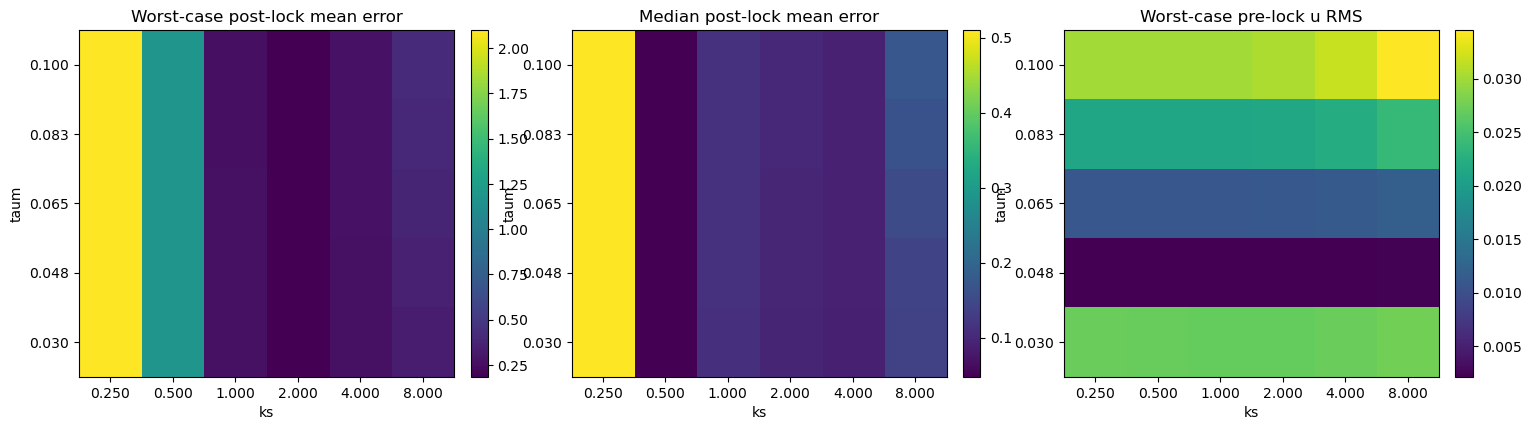

,taum,ks,worst_post_lock_abs_mean_error,median_post_lock_abs_mean_error,worst_pre_lock_u_rms,phase_sensitivity_span
0,0.1000,2.0,0.1847,0.1011,0.0306,0.1824
1,0.0300,2.0,0.1855,0.0949,0.0269,0.1728
2,0.0825,2.0,0.1859,0.0996,0.0215,0.1842
3,0.0650,2.0,0.1867,0.0981,0.0110,0.1813
4,0.0475,2.0,0.1869,0.0967,0.0021,0.1778
5,0.1000,1.0,0.2620,0.1135,0.0301,0.2287
6,0.0825,1.0,0.2646,0.1135,0.0213,0.2307
7,0.0650,1.0,0.2671,0.1134,0.0109,0.2326
8,0.0300,4.0,0.2673,0.0884,0.0271,0.2270
9,0.0475,1.0,0.2697,0.1131,0.0021,0.2346


In [81]:
def plot_heatmap(ax, value_col, title):
    pivot = agg_df.pivot(index='taum', columns='ks', values=value_col)
    pivot = pivot.reindex(index=sorted(pivot.index, reverse=True), columns=sorted(pivot.columns))
    im = ax.imshow(pivot.values, aspect='auto')
    ax.set_title(title)
    ax.set_xlabel('ks')
    ax.set_ylabel('taum')
    ax.set_xticks(np.arange(len(pivot.columns)), labels=[f'{x:.03f}' for x in pivot.columns])
    ax.set_yticks(np.arange(len(pivot.index)), labels=[f'{x:.03f}' for x in pivot.index])
    #for row in range(pivot.shape[0]):
    #    for col in range(pivot.shape[1]):
    #        ax.text(col, row, f'{pivot.values[row, col]:.3f}', ha='center', va='center', color='w', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    #ax.set_yscale('log')


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
plot_heatmap(axes[0], 'worst_post_lock_abs_mean_error', 'Worst-case post-lock mean error')
plot_heatmap(axes[1], 'median_post_lock_abs_mean_error', 'Median post-lock mean error')
plot_heatmap(axes[2], 'worst_pre_lock_u_rms', 'Worst-case pre-lock u RMS')
plt.show()

agg_df[
    [
        'taum', 'ks', 'worst_post_lock_abs_mean_error',
        'median_post_lock_abs_mean_error', 'worst_pre_lock_u_rms',
        'phase_sensitivity_span',
    ]
].head(12).round(4)
